# Лабораторна робота 5. Власне донавчання: Text-to-SQL із QLoRA (Qwen3-4B)

## 1.1. Задача

**Опис задачі та практичне застосування.**  
Потрібно створити локальний модуль генерації SQL-запитів (Text-to-SQL) для внутрішнього аналітичного інструмента або чат-бота бізнес-аналітиків.
- **Користувач:** продакт-менеджер, аналітик або backend-сервіс, що формує звіти з реляційної БД.
- **Вхід:** схема таблиць у форматі DDL (`CREATE TABLE ...`) та запит користувача природною мовою (англійською).
- **Вихід:** єдиний готовий до виконання SQL-запит **без жодного додаткового тексту, пояснень чи Markdown-блоків** (щоб рядок можна було одразу передати у SQL-парсер / read-only рушій БД).

**Чому потрібне саме донавчання, а не промпт чи RAG:**
- **Недоліки промпту:** загальна instruct-модель навіть із детальним системним промптом часто додає пояснення, обгортає код у ```` ```sql ... ``` ````, вигадує неіснуючі псевдоніми або використовує діалектні конструкції замість лаконічного стандартного SQL. Крім того, довгі системні інструкції з прикладами (few-shot) збільшують затримку та витрату токенів на кожному запиті.
- **Чому не RAG:** схема конкретної таблиці вже подається безпосередньо в запиті; проблема полягає не у нестачі зовнішніх фактів, а у **стабільній поведінці та строгому форматі генерації**, що є класичним випадком для SFT-донавчання.


In [13]:
!pip install -q "transformers>=4.55.0" "trl>=1.17" "peft" "bitsandbytes" "datasets" "accelerate" "matplotlib" "pandas"
!pip uninstall -q -y torchao

import gc
import os
import re
import sqlite3
import time

import matplotlib.pyplot as plt
import pandas as pd
import torch
from datasets import load_dataset
from peft import LoraConfig
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig, set_seed
from trl import SFTConfig, SFTTrainer

set_seed(42)
assert torch.cuda.is_available(), "Потрібна GPU (Colab T4 або локальна NVIDIA GPU)"
print(f"GPU: {torch.cuda.get_device_name()}")
print(f"Памʼять GPU: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

GPU: Tesla T4
Памʼять GPU: 15.6 GB


## 1.2. Модель і дані

- **Модель:** `Qwen/Qwen3-4B` (instruct-модель, ~4,02 млрд параметрів).  
  *Обґрунтування:* instruct-версія вже володіє синтаксисом SQL і шаблоном розмови ChatML (з керуванням `enable_thinking=False`), тому потребує значно менше даних і кроків SFT, ніж base-модель. Розмір 4B є оптимальним балансом між якістю розуміння складних схем БД і можливістю донавчання методом **QLoRA (4-bit NF4)** на GPU з 12–16 GB VRAM.
- **Дані:** датасет [`b-mc2/sql-create-context`](https://huggingface.co/datasets/b-mc2/sql-create-context) (зібраний на основі WikiSQL та Spider; ліцензія — див. картку датасету на Hugging Face, `cc-by-sa-4.0` / відкритий академічний доступ). Містить 78 577 прикладів із полями `context` (DDL-схема `CREATE TABLE`), `question` (запит користувача) та `answer` (еталонний SQL).
- **Поділ (без витоку даних):** після дедуплікації та перемішування (`seed=42`) формуємо:
  - `train`: **2 000** прикладів;
  - `validation`: **200** прикладів (для контролю `eval_loss` і перенавчання);
  - `test`: **300** прикладів (повністю ізольовані, використовуються лише для фінальної оцінки до/після).

In [14]:
MODEL_NAME = "Qwen/Qwen3-4B"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

raw_ds = load_dataset("b-mc2/sql-create-context", split="train")
print(raw_ds)

# Покажемо 3 оригінальні приклади
for i in range(3):
    ex = raw_ds[i]
    print(f"\n--- Приклад {i+1} ---")
    print("Schema:  ", ex["context"])
    print("Question:", ex["question"])
    print("SQL:     ", ex["answer"])

# Дедуплікація за парою (context, question)
seen, keep = set(), []
for i, (ctx, q) in enumerate(zip(raw_ds["context"], raw_ds["question"])):
    key = (ctx.strip().lower(), q.strip().lower())
    if key not in seen:
        seen.add(key)
        keep.append(i)

dedup_ds = raw_ds.select(keep).shuffle(seed=42)
print(f"\nДо дедуплікації: {len(raw_ds)}, після: {len(dedup_ds)}")

SHORT_SYSTEM_PROMPT = "Translate the user question into a valid SQL query using the provided schema. Output SQL only."

BEST_BASELINE_PROMPT = """You are an expert SQL generator for an automated database pipeline.
Given a SQLite table schema (CREATE TABLE) and a natural language question, output ONLY a single executable SQL query.
Strict rules:
1. Do NOT include markdown code fences (no ```sql or ```).
2. Do NOT add explanations, comments, or trailing semicolons unless needed.
3. Use ONLY table and column names present in the provided schema.
4. Keep the query concise and match standard SQL syntax."""


def to_messages(example):
    user_content = f"Schema:\n{example['context']}\n\nQuestion:\n{example['question']}"
    return {
        "messages": [
            {"role": "system", "content": SHORT_SYSTEM_PROMPT},
            {"role": "user", "content": user_content},
            {"role": "assistant", "content": example["answer"].strip()},
        ],
        "context": example["context"],
        "question": example["question"],
        "target_sql": example["answer"].strip(),
        "chat_template_kwargs": {"enable_thinking": False},
    }


train_dataset = dedup_ds.select(range(0, 2000)).map(to_messages, remove_columns=dedup_ds.column_names)
val_dataset = dedup_ds.select(range(2000, 2200)).map(to_messages, remove_columns=dedup_ds.column_names)
test_dataset = dedup_ds.select(range(2200, 2500)).map(to_messages, remove_columns=dedup_ds.column_names)

# Для SFTTrainer залишаємо тільки колонки messages і chat_template_kwargs
train_sft = train_dataset.remove_columns(["context", "question", "target_sql"])
val_sft = val_dataset.remove_columns(["context", "question", "target_sql"])


def count_chat_tokens(messages):
    encoded = tokenizer.apply_chat_template(messages, tokenize=True, enable_thinking=False)
    return len(encoded["input_ids"]) if hasattr(encoded, "keys") else len(encoded)


max_train_tokens = max(count_chat_tokens(m) for m in train_sft["messages"])
print(f"Train: {len(train_sft)}, Val: {len(val_sft)}, Test: {len(test_dataset)}")
print(f"Максимальна довжина діалогу в train: {max_train_tokens} токенів (ліміт max_length=512)")
print(f"Токенів у короткому промпті: {len(tokenizer(SHORT_SYSTEM_PROMPT)['input_ids'])}")
print(f"Токенів у детальному промпті: {len(tokenizer(BEST_BASELINE_PROMPT)['input_ids'])}")
print("\n--- Відформатований приклад для SFT ---")
print(tokenizer.apply_chat_template(train_sft[0]["messages"], tokenize=False, enable_thinking=False))

Dataset({
    features: ['answer', 'question', 'context'],
    num_rows: 78577
})

--- Приклад 1 ---
Schema:   CREATE TABLE head (age INTEGER)
Question: How many heads of the departments are older than 56 ?
SQL:      SELECT COUNT(*) FROM head WHERE age > 56

--- Приклад 2 ---
Schema:   CREATE TABLE head (name VARCHAR, born_state VARCHAR, age VARCHAR)
Question: List the name, born state and age of the heads of departments ordered by age.
SQL:      SELECT name, born_state, age FROM head ORDER BY age

--- Приклад 3 ---
Schema:   CREATE TABLE department (creation VARCHAR, name VARCHAR, budget_in_billions VARCHAR)
Question: List the creation year, name and budget of each department.
SQL:      SELECT creation, name, budget_in_billions FROM department

До дедуплікації: 78577, після: 78573
Train: 2000, Val: 200, Test: 300
Максимальна довжина діалогу в train: 224 токенів (ліміт max_length=512)
Токенів у короткому промпті: 18
Токенів у детальному промпті: 96

--- Відформатований приклад для SFT 

## 1.3. Модель до донавчання

**Вибір метрик:**
1. **Чистий SQL (без обгорток/коментарів), %** — чи починається відповідь безпосередньо із ключового слова `SELECT` або `WITH` без Markdown-блоків ```` ``` ```` і зайвого пояснювального тексту. Критично для автоматичної передачі рядка в БД-драйвер.
2. **Валідність у SQLite (синтаксис + схема), %** — створюємо тимчасову in-memory базу `sqlite3`, виконуємо `CREATE TABLE` зі схеми й перевіряємо згенерований запит через `EXPLAIN <sql>`. Це перевіряє граматику SQL та існування таблиць і колонок (із застереженням: якщо в запиті замість назви колонки підставлено числовий літерал, наприклад `WHERE 1969 = 54.3`, SQLite сприймає його як константу і вважає запит синтаксично валідним).
3. **Нормалізований Exact Match (EM), %** — точний збіг згенерованого SQL з еталонним після зведення регістру, пробілів і видалення кінцевої крапки з комою (додатково відстежується варіант без урахування типу лапок `'...'` vs `"..."`, оскільки стандартний SQL використовує одинарні лапки, а еталони датасету — подвійні).

In [15]:
def strip_sql_fences(text: str) -> str:
    s = text.strip()
    if s.startswith("```"):
        s = re.sub(r"^```(?:sql)?\s*", "", s, flags=re.IGNORECASE)
        s = re.sub(r"\s*```$", "", s)
    return s.strip()


def is_clean_sql(text: str) -> bool:
    s = text.strip()
    if "```" in s or "\n" in s:
        return False
    return bool(re.match(r"^(SELECT|WITH)\b", s, flags=re.IGNORECASE))


def normalize_sql(sql: str, unify_quotes: bool = False) -> str:
    s = strip_sql_fences(sql).strip().rstrip(";")
    if unify_quotes:
        s = s.replace("'", '"')
    s = re.sub(r"\s+", " ", s)
    s = re.sub(r"\s*([(),=<>!]+)\s*", r" \1 ", s)
    s = re.sub(r"\s+", " ", s).strip().lower()
    return s


def is_valid_sqlite(schema: str, sql: str) -> bool:
    clean = strip_sql_fences(sql)
    try:
        with sqlite3.connect(":memory:") as conn:
            conn.executescript(schema)
            conn.execute(f"EXPLAIN {clean}")
        return True
    except Exception:
        return False


def generate_batch(model, user_prompts, system_prompt, max_new_tokens=128):
    formatted = [
        tokenizer.apply_chat_template(
            [{"role": "system", "content": system_prompt}, {"role": "user", "content": p}],
            tokenize=False,
            add_generation_prompt=True,
            enable_thinking=False,
        )
        for p in user_prompts
    ]
    tokenizer.padding_side = "left"
    inputs = tokenizer(formatted, return_tensors="pt", padding=True).to(model.device)
    tokenizer.padding_side = "right"
    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=tokenizer.pad_token_id,
            eos_token_id=tokenizer.eos_token_id,
        )
    new_tokens = outputs[:, inputs["input_ids"].shape[1]:]
    return [ans.strip() for ans in tokenizer.batch_decode(new_tokens, skip_special_tokens=True)]


def evaluate_sql(model, system_prompt, batch_size=16):
    model.eval()
    user_prompts = [ex["messages"][1]["content"] for ex in test_dataset]
    schemas = test_dataset["context"]
    targets = test_dataset["target_sql"]
    questions = test_dataset["question"]

    preds = []
    for start in range(0, len(user_prompts), batch_size):
        preds += generate_batch(model, user_prompts[start:start + batch_size], system_prompt)

    clean_ok = sqlite_ok = em_ok = em_quotes_ok = 0
    records = []
    for q, sch, tgt, pred in zip(questions, schemas, targets, preds):
        c = is_clean_sql(pred)
        v = is_valid_sqlite(sch, pred)
        e = normalize_sql(pred, unify_quotes=False) == normalize_sql(tgt, unify_quotes=False)
        eq = normalize_sql(pred, unify_quotes=True) == normalize_sql(tgt, unify_quotes=True)
        clean_ok += c
        sqlite_ok += v
        em_ok += e
        em_quotes_ok += eq
        records.append({
            "question": q, "schema": sch, "target": tgt, "pred": pred,
            "clean": c, "valid_sqlite": v, "exact_match": e, "exact_match_unquoted": eq,
        })

    n = len(preds)
    metrics = {
        "Чистий SQL, %": round(100 * clean_ok / n, 2),
        "Валідний SQLite, %": round(100 * sqlite_ok / n, 2),
        "Exact Match, %": round(100 * em_ok / n, 2),
        "EM (без різниці лапок), %": round(100 * em_quotes_ok / n, 2),
    }
    return metrics, records


# Очищаємо відеопам'ять перед завантаженням моделі (на випадок повторного запуску клітинки)
for var_name in ("trainer", "model"):
    if var_name in globals():
        del globals()[var_name]
gc.collect()
torch.cuda.empty_cache()

# Завантажуємо Qwen3-4B у 4-біт NF4 (QLoRA-конфігурація)
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    quantization_config=bnb_config,
    device_map="auto",
)
print(f"Памʼять GPU після завантаження (4-bit NF4): {torch.cuda.memory_allocated() / 1e9:.2f} GB")

# Оцінюємо ДО донавчання з найкращим детальним промптом
before_metrics, before_records = evaluate_sql(model, BEST_BASELINE_PROMPT)
print("\nМетрики ДО донавчання (детальний промпт):", before_metrics)

print("\n--- 8 прикладів відповідей ДО донавчання ---")
for i, r in enumerate(before_records[:8], 1):
    print(f"[{i}] Q: {r['question']}")
    print(f"    Еталон: {r['target']}")
    print(f"    Модель: {r['pred']}")
    print(f"    clean={r['clean']} | sqlite={r['valid_sqlite']} | EM={r['exact_match']} | EM_quotes={r['exact_match_unquoted']}\n")

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Памʼять GPU після завантаження (4-bit NF4): 2.70 GB

Метрики ДО донавчання (детальний промпт): {'Чистий SQL, %': 96.67, 'Валідний SQLite, %': 97.67, 'Exact Match, %': 5.0, 'EM (без різниці лапок), %': 53.0}

--- 8 прикладів відповідей ДО донавчання ---
[1] Q: Who was the opponent with a score of 109–108?
    Еталон: SELECT opponent FROM table_name_7 WHERE score = "109–108"
    Модель: SELECT opponent FROM table_name_7 WHERE score = '109–108';
    clean=True | sqlite=True | EM=False | EM_quotes=True

[2] Q: Who won on 2007-04-14
    Еталон: SELECT result FROM table_name_66 WHERE date = "2007-04-14"
    Модель: SELECT result FROM table_name_66 WHERE date = '2007-04-14';
    clean=True | sqlite=True | EM=False | EM_quotes=True

[3] Q: What institution is located in Watertown, Wisconsin?
    Еталон: SELECT institution FROM table_1974443_1 WHERE location = "Watertown, Wisconsin"
    Модель: SELECT institution FROM table_1974443_1 WHERE location = 'Watertown, Wisconsin';
    clean=True | sql

## 1.4. Донавчання (SFT + QLoRA)

**Метод і обґрунтування гіперпараметрів:**
- **QLoRA (4-bit NF4 + LoRA):** базові ваги заморожуються в 4-бітному форматі NF4, тренуються лише адаптери в усіх лінійних шарах (`target_modules="all-linear"`), що знижує пікову пам'ять GPU з >60 GB (повне донавчання) до ~4 GB на GPU Tesla T4 (15.6 GB VRAM).
- **`r=16`, `lora_alpha=32`, `lora_dropout=0.05`:** стандартний ранг для структурованої генерації (масштаб `α/r = 2`), достатній для засвоєння синтаксичних правил без втрати загальних здібностей.
- **`learning_rate=1e-4`** з косинусним розкладом і `warmup_steps=10`: під час попереднього експерименту з `learning_rate=2e-4` валідаційний `eval_loss` знижувався монотонно, але модель частково перенавчилася під надкороткий формат відповідей (на короткому загальному питанні *«What is the capital of France?»* передчасно завершувала генерацію після службового слова). Зменшення кроку навчання до `1e-4` та збільшення контексту до `max_length=512` усуває перенавчання формату при збереженні високої якості Text-to-SQL.
- **Батч:** `per_device_train_batch_size=4`, `gradient_accumulation_steps=4` → ефективний розмір батча **16 прикладів**.
- **Тривалість:** `max_steps=125` (1 повна епоха по 2 000 прикладів), `eval_steps=25` для контролю `validation loss`.
- **`assistant_only_loss=True`:** функція втрат обчислюється лише на токенах згенерованого SQL.

trainable params: 33,030,144 || all params: 4,055,498,240 || trainable%: 0.8145


Step,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
25,0.696663,0.133783,0.114953,0.967182,40314.000000
50,0.097211,0.095125,0.085130,0.977692,80037.000000
75,0.074719,0.077363,0.057075,0.980886,120471.000000
100,0.064494,0.068379,0.069903,0.982341,160763.000000
125,0.062314,0.066834,0.070356,0.981989,201472.000000



Тривалість тренування: 14.90 хв
Пікова памʼять GPU: 3.91 GB
Розмір збереженого адаптера: 132.2 MB


,step,train_loss,eval_loss
0,25,0.6967,0.1338
1,50,0.0972,0.0951
2,75,0.0747,0.0774
3,100,0.0645,0.0684
4,125,0.0623,0.0668


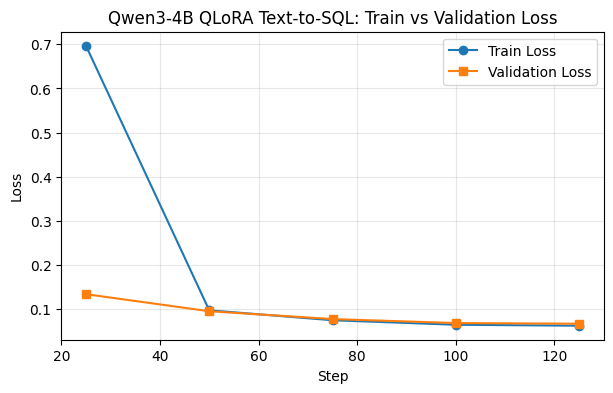

In [16]:
peft_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    target_modules="all-linear",
    task_type="CAUSAL_LM",
)

sft_config = SFTConfig(
    output_dir="qwen3-4b-sql-qlora",
    max_length=512,
    per_device_train_batch_size=4,
    gradient_accumulation_steps=4,   # ефективний батч = 16
    per_device_eval_batch_size=8,
    learning_rate=1e-4,
    lr_scheduler_type="cosine",
    warmup_steps=10,
    max_steps=125,                   # 125 × 16 = 2000 прикладів (1 епоха)
    eval_strategy="steps",
    eval_steps=25,
    logging_steps=25,
    fp16=True,
    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False},
    assistant_only_loss=True,
    save_strategy="no",
    report_to="none",
    seed=42,
)

torch.cuda.reset_peak_memory_stats()
trainer = SFTTrainer(
    model=model,
    args=sft_config,
    train_dataset=train_sft,
    eval_dataset=val_sft,
    processing_class=tokenizer,
    peft_config=peft_config,
)

# Для сумісності fp16 з 4-бітними моделями на T4 переводимо треновані ваги адаптера у fp32
if getattr(model, "is_loaded_in_4bit", False):
    for param in trainer.model.parameters():
        if param.requires_grad:
            param.data = param.data.float()

trainer.model.print_trainable_parameters()

start_time = time.time()
trainer.train()
train_minutes = (time.time() - start_time) / 60
peak_vram_gb = torch.cuda.max_memory_allocated() / 1e9

print(f"\nТривалість тренування: {train_minutes:.2f} хв")
print(f"Пікова памʼять GPU: {peak_vram_gb:.2f} GB")

# Зберігаємо адаптер локально (НЕ додавати в Git-репозиторій!)
ADAPTER_DIR = "qwen3-4b-sql-qlora-adapter"
trainer.save_model(ADAPTER_DIR)
adapter_mb = os.path.getsize(os.path.join(ADAPTER_DIR, "adapter_model.safetensors")) / 1e6
print(f"Розмір збереженого адаптера: {adapter_mb:.1f} MB")

# Таблиця і графік training & validation loss
train_logs = [(h["step"], h["loss"]) for h in trainer.state.log_history if "loss" in h]
eval_logs = [(h["step"], h["eval_loss"]) for h in trainer.state.log_history if "eval_loss" in h]

loss_df = pd.merge(
    pd.DataFrame(train_logs, columns=["step", "train_loss"]),
    pd.DataFrame(eval_logs, columns=["step", "eval_loss"]),
    on="step",
    how="outer",
).sort_values("step")
display(loss_df.round(4))

plt.figure(figsize=(7, 4))
plt.plot([x[0] for x in train_logs], [x[1] for x in train_logs], marker="o", label="Train Loss")
plt.plot([x[0] for x in eval_logs], [x[1] for x in eval_logs], marker="s", label="Validation Loss")
plt.xlabel("Step")
plt.ylabel("Loss")
plt.title("Qwen3-4B QLoRA Text-to-SQL: Train vs Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 1.5. Порівняння до і після донавчання, аналіз помилок та загальні запити

In [17]:
# Оцінюємо ПІСЛЯ донавчання з КОРОТКИМ промптом
after_metrics, after_records = evaluate_sql(trainer.model, SHORT_SYSTEM_PROMPT)

comparison_df = pd.DataFrame({
    "До донавчання (детальний промпт)": before_metrics,
    "Після QLoRA (короткий промпт)": after_metrics,
})
comparison_df["Зміна (Δ)"] = (
    comparison_df["Після QLoRA (короткий промпт)"] - comparison_df["До донавчання (детальний промпт)"]
).round(2)
display(comparison_df)

print("\n--- Порівняння на тих самих 8 прикладах ---")
for i in range(8):
    b, a = before_records[i], after_records[i]
    print(f"[{i+1}] Q: {b['question']}")
    print(f"    Еталон: {b['target']}")
    print(f"    До:     {b['pred']}  (EM={b['exact_match']}, SQLite={b['valid_sqlite']})")
    print(f"    Після:  {a['pred']}  (EM={a['exact_match']}, SQLite={a['valid_sqlite']})\n")

print("\n--- Аналіз помилок донавченої моделі (перші 10 незбігів за EM) ---")
errors = [r for r in after_records if not r["exact_match"]]
print(f"Усього незбігів за Exact Match: {len(errors)} із {len(after_records)}")
for i, r in enumerate(errors[:10], 1):
    print(f"[Помилка {i}] Q: {r['question']}")
    print(f"    Schema: {r['schema']}")
    print(f"    Еталон: {r['target']}")
    print(f"    Модель: {r['pred']}  (SQLite valid={r['valid_sqlite']})\n")

# Перевірка на загальних запитах поза задачею (чи немає катастрофічного забування)
general_questions = [
    "What is the capital of France?",
    "Explain recursion in programming in 2 simple sentences.",
    "Give 3 tips for writing clean code.",
]
general_answers = generate_batch(
    trainer.model,
    general_questions,
    system_prompt="You are a helpful assistant.",
    max_new_tokens=100,
)
print("\n--- Перевірка на загальних запитах (поза SQL) ---")
for q, ans in zip(general_questions, general_answers):
    print(f"❓ {q}\n💬 {ans}\n" + "-" * 50)

,До донавчання (детальний промпт),Після QLoRA (короткий промпт),Зміна (Δ)
"Чистий SQL, %",96.67,100.00,3.33
"Валідний SQLite, %",97.67,98.67,1.00
"Exact Match, %",5.00,69.67,64.67
"EM (без різниці лапок), %",53.00,69.67,16.67



--- Порівняння на тих самих 8 прикладах ---
[1] Q: Who was the opponent with a score of 109–108?
    Еталон: SELECT opponent FROM table_name_7 WHERE score = "109–108"
    До:     SELECT opponent FROM table_name_7 WHERE score = '109–108';  (EM=False, SQLite=True)
    Після:  SELECT opponent FROM table_name_7 WHERE score = "109–108"  (EM=True, SQLite=True)

[2] Q: Who won on 2007-04-14
    Еталон: SELECT result FROM table_name_66 WHERE date = "2007-04-14"
    До:     SELECT result FROM table_name_66 WHERE date = '2007-04-14';  (EM=False, SQLite=True)
    Після:  SELECT result FROM table_name_66 WHERE date = "2007-04-14"  (EM=True, SQLite=True)

[3] Q: What institution is located in Watertown, Wisconsin?
    Еталон: SELECT institution FROM table_1974443_1 WHERE location = "Watertown, Wisconsin"
    До:     SELECT institution FROM table_1974443_1 WHERE location = 'Watertown, Wisconsin';  (EM=False, SQLite=True)
    Після:  SELECT institution FROM table_1974443_1 WHERE location = "Watertow

In [20]:
from huggingface_hub import login
login()
trainer.model.push_to_hub("ipz235bvv/qwen3-4b-sql-qlora-adapter")
tokenizer.push_to_hub("ipz235bvv/qwen3-4b-sql-qlora-adapter")

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...adapter_model.safetensors:   0%|          | 60.9kB /  132MB            

Validating                    :           |   0%            

README.md:   0%|          | 0.00/5.17k [00:00<?, ?B/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...mp6hx9ueyq/tokenizer.json:   0%|          | 28.5kB / 11.4MB            

Validating                    :           |   0%            

CommitInfo(commit_url='https://huggingface.co/ipz235bvv/qwen3-4b-sql-qlora-adapter/commit/feca4e12f7fc9fb762be5dc556c168248eb7d373', commit_message='Upload tokenizer', commit_description='', oid='feca4e12f7fc9fb762be5dc556c168248eb7d373', pr_url=None, repo_url=RepoUrl('https://huggingface.co/ipz235bvv/qwen3-4b-sql-qlora-adapter', endpoint='https://huggingface.co', repo_type='model', repo_id='ipz235bvv/qwen3-4b-sql-qlora-adapter'), pr_revision=None, pr_num=None)

## 1.6. Мій звіт

- **Задача і чому потрібне донавчання:** Автоматичне перетворення запитів користувачів природною мовою на виконуваний SQL-запит за заданою DDL-схемою (`CREATE TABLE`) для інтеграції у внутрішній аналітичний сервіс (Text-to-SQL). Без донавчання загальна instruct-модель використовує стандартний діалект (одинарні лапки `'...'`, кінцеву крапку з комою `;`, узагальнені агрегації на кшталт `COUNT(*)` замість цільової колонки), іноді додає пояснення або обгортки та вимагає довгого системного промпту з правилами на кожному виклику. RAG тут не розв'язує проблему, оскільки DDL-схема конкретної таблиці вже подається безпосередньо у вхідному запиті — потрібна саме адаптація поведінки й строгого формату виводу моделі.
- **Модель і дані:** Обрано instruct-модель `Qwen/Qwen3-4B` (~4,02 млрд параметрів). Використано датасет `b-mc2/sql-create-context` (78 577 прикладів пар «DDL-схема + запитання → SQL» на основі WikiSQL та Spider; ліцензія `cc-by-sa-4.0`). Після дедуплікації за парою `(context, question)` (залишилося 78 573 унікальні записи) та перемішування (`seed=42`) сформовано ізольовані вибірки: 2 000 тренувальних, 200 валідаційних і 300 тестових прикладів у форматі `messages` із вимкненим режимом міркувань (`enable_thinking=False`).
- **Метрика й результат до донавчання:** Оцінювання проводилося на 300 тестових прикладах за чотирма метриками: частка чистого однорядкового SQL без зайвого тексту й Markdown-обгорток (`Чистий SQL`), синтаксично-схемна валідність у `sqlite3` через `EXPLAIN` (`Валідний SQLite`), суворий нормалізований `Exact Match` (`EM`) та `EM (без різниці лапок)`. До донавчання (з детальним промптом на **96 токенів**) модель показала: Чистий SQL — **96.67%**, Валідний SQLite — **97.67%**, суворий Exact Match — **5.00%**, EM без різниці лапок — **53.00%**. Розрив між суворим EM (`5.00%`) і EM без різниці лапок (`53.00%`) наочно підтверджує, що базова модель генерує коректний SQL, але в іншому стилі форматування (`'...'` замість `"..."`, кінцеві `;` та інші агрегації).
- **Метод донавчання й гіперпараметри:** Використано SFT із методом **QLoRA (4-bit NF4, double quantization)**, що зменшило обсяг завантаженої моделі в пам'яті GPU до **2.70 GB** і дозволило провести тренування на GPU Tesla T4 (15.6 GB VRAM). Параметри LoRA: `r=16`, `lora_alpha=32`, `lora_dropout=0.05`, `target_modules="all-linear"` (тренувалося 33 030 144 параметри — **0.8145%** від загальної кількості). Параметри тренування: `learning_rate=1e-4` (знижено з `2e-4` для уникнення перенавчання під надкороткий формат відповідей, cosine schedule, `warmup_steps=10`), ефективний батч `16` (`4 × 4`), `125` кроків (1 епоха по 2 000 прикладах), `max_length=512` (максимальна фактична довжина діалогу в `train` становить 224 токени), `fp16=True`, `assistant_only_loss=True`, `gradient_checkpointing=True`. Тривалість тренування: **14.90 хв**, пікова пам'ять GPU: **3.91 GB**, розмір збереженого адаптера: **132.2 MB**. Графік і таблиця втрат показали монотонне зниження `train_loss` (з `0.6967` на кроці 25 до `0.0623` на кроці 125) та `eval_loss` (з `0.1338` до `0.0668`) без ознак перенавчання.
- **Результат після донавчання:** На тому самому тестовому наборі з 300 прикладів, але вже з коротким системним промптом (**18 токенів** — у **5,33 раза** коротшим, економія 78 токенів на кожен запит), донавчена модель досягла приросту за всіма чотирма метриками: Чистий SQL — **100.00%** (`Δ = +3.33%`), Валідний SQLite — **98.67%** (`Δ = +1.00%`), суворий Exact Match — **69.67%** (`Δ = +64.67%`), EM без різниці лапок — **69.67%** (`Δ = +16.67%`). На всіх трьох загальних запитах поза задачею SQL модель дала точні, розгорнуті й адекватні відповіді без ознак катастрофічного забування.
- **Аналіз помилок:** Із 300 тестових прикладів незбіг за суворим Exact Match зафіксовано у **91 випадку (30.33%)**. Детальний аналіз перших 10 незбігів показав, що **8 із 10 випадків не є змістовними помилками генерації SQL**:
  1. **Типізація літералів у `VARCHAR`-колонках (5 із 10 — помилки #1, #3, #6, #7, #10):** модель брала числові значення у подвійні лапки (`"10"`, `"320"`, `"21"`, `"71"`), дотримуючись типу `VARCHAR` із DDL-схеми, тоді як в еталонах WikiSQL числа записані без лапок (або навпаки — `hole = 1` vs `"1"` у #3).
  2. **Дефекти розмітки в еталонах датасету WikiSQL (2 із 10 — помилки #4, #9):** у #4 запитання явно вимагає *«with a round less than 6»* і модель правильно згенерувала `round < 6`, тоді як в еталоні міститься помилкове `round > 6`; у #9 число `54,714` через кому зламало парсер WikiSQL в еталоні (`WHERE attendance = 54 OFFSET 714`), тоді як модель згенерувала коректний запит `WHERE attendance = "54,714"`.
  3. **Семантично еквівалентний порядок умов у `WHERE` (1 із 10 — помилка #2):** `WHERE location = "safeco field" AND opponent = "boston red sox" AND decision = "l"` замість іншого порядку тих самих кон'юнкцій.
  4. **Реальні неточності генерації та дефекти неповних схем (2 із 10 — помилки #5, #8):** у #8 модель правильно зберегла спецсимвол `*` у `"*ni-da"`, пропустивши лише псевдонім колонки `AS polite`; у #5 на прикладі з неповною DDL-схемою (`Id VARCHAR`, де числові назви колонок `2000`, `1969`, `1979` відсутні в `CREATE TABLE`) модель згенерувала `SELECT 2000` замість `SELECT SUM(2000)`.
- **Висновок:** Донавчання `Qwen/Qwen3-4B` методом QLoRA на 2 000 прикладах дозволило підвищити сувору точність `Exact Match` на тестовій вибірці з **5.00% до 69.67% (`+64.67 п.п.`)**, забезпечити **100.00%** чистого однорядкового SQL і **98.67%** синтаксично-схемної валідності в SQLite при скороченні системного промпту в **5,33 раза** (з 96 до 18 токенів). Адаптер займає лише **132.2 MB**, тренується за **14.90 хв** із піковим споживанням **3.91 GB** VRAM і повністю зберігає загальні діалогові здібності моделі. Опублікований адаптер на Hugging Face Hub: https://huggingface.co/ipz235bvv/qwen3-4b-sql-qlora-adapter